#Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
import joblib

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
print('Libraries imported successfully')

Libraries imported successfully


#Load the Dataset

In [2]:
file_path = r'C:\Users\user\Downloads\Unified_Leads.csv'
df = pd.read_csv(file_path)

print('Rows, Columns :', df.shape)
df.head()

Rows, Columns : (27375, 15)


,Name,contact_number,Contact_email,creation_date,first_call_attempt,lead_status,lead_stage,lead_tag,assigned_to,last_call_date,last_call_time,references,campaign_name,source_type,source_name
0,Anjali Singh,9931980478,anjali.singh878@hotmail.com,03-02-2026 22:31,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
1,Kiran Bose,6474315136,kiran.bose601@example.com,03-02-2026 21:46,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,FACEBOOK_ADS,FACEBOOK_ADS
2,Karthik Malhotra,6753707898,karthik.malhotra329@example.com,03-02-2026 21:28,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
3,Anjali Sharma,9439163624,anjali.sharma85@example.com,03-02-2026 19:59,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
4,Sneha Kapoor,9878269840,sneha.kapoor46@gmail.com,03-02-2026 19:19,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM


#Understand the Data

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27375 entries, 0 to 27374
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                27375 non-null  object 
 1   contact_number      27375 non-null  int64  
 2   Contact_email       27375 non-null  object 
 3   creation_date       27375 non-null  object 
 4   first_call_attempt  20646 non-null  object 
 5   lead_status         27375 non-null  object 
 6   lead_stage          27375 non-null  object 
 7   lead_tag            15959 non-null  object 
 8   assigned_to         27375 non-null  object 
 9   last_call_date      20646 non-null  object 
 10  last_call_time      20646 non-null  object 
 11  references          0 non-null      float64
 12  campaign_name       27375 non-null  object 
 13  source_type         27375 non-null  object 
 14  source_name         27375 non-null  object 
dtypes: float64(1), int64(1), object(13)
memory usage: 3.1

In [4]:
missing = df.isnull().sum().to_frame('missing_count')
missing['missing_%'] = (missing['missing_count'] / len(df) * 100).round(2)
missing

,missing_count,missing_%
Name,0,0.00
contact_number,0,0.00
Contact_email,0,0.00
creation_date,0,0.00
first_call_attempt,6729,24.58
lead_status,0,0.00
lead_stage,0,0.00
lead_tag,11416,41.70
assigned_to,0,0.00
last_call_date,6729,24.58


In [5]:
for col in ['lead_stage', 'lead_status', 'lead_tag', 'source_type']:
    print(df[col].value_counts(dropna=False))
    print('-' * 40)

lead_stage
LOST                  11698
Prospect              10119
Follow Up Required     4713
CONVERTED               845
Name: count, dtype: int64
----------------------------------------
lead_status
CLOSED                                   12279
PENDING WITH EXECUTIVE                    7947
NOT CONNECTED - RESCHEDULED BY SYSTEM     3857
RESCHEDULED BY EXECUTIVE                  2962
NOT CONNECTED - CLOSED BY SYSTEM           328
OPEN                                         2
Name: count, dtype: int64
----------------------------------------
lead_tag
NaN                    11416
not-interested         10869
cold                    4024
warm                     446
lost-to-competition      303
hot                      236
call-not-connected        52
already-purchased         29
Name: count, dtype: int64
----------------------------------------
source_type
INSTAGRAM           18182
FILE_UPLOAD          5130
MOVE_LEAD            2848
FACEBOOK_ADS         1193
WALK_IN_LEAD           21

#Data Cleaning

In [6]:
df_clean = df.copy()

# 1. Remove duplicate rows
print('Duplicate rows found:', df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()

# 2. Remove extra spaces from text columns
print('Unique salespeople BEFORE cleaning:', df_clean['assigned_to'].nunique())
text_cols = ['assigned_to', 'campaign_name', 'source_type', 'lead_stage', 'lead_status']
for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()
print('Unique salespeople AFTER cleaning :', df_clean['assigned_to'].nunique())

# 3. Drop columns that are not useful
drop_cols = ['Name', 'contact_number', 'Contact_email', 'references', 'source_name', 'last_call_time']
df_clean = df_clean.drop(columns=drop_cols)

print('Shape after cleaning:', df_clean.shape)
df_clean.head()

Duplicate rows found: 0
Unique salespeople BEFORE cleaning: 26
Unique salespeople AFTER cleaning : 25
Shape after cleaning: (27375, 9)


,creation_date,first_call_attempt,lead_status,lead_stage,lead_tag,assigned_to,last_call_date,campaign_name,source_type
0,03-02-2026 22:31,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,Data Analytics Knovista,INSTAGRAM
1,03-02-2026 21:46,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,Data Analytics Knovista,FACEBOOK_ADS
2,03-02-2026 21:28,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,Data Analytics Knovista,INSTAGRAM
3,03-02-2026 19:59,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,Data Analytics Knovista,INSTAGRAM
4,03-02-2026 19:19,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,Data Analytics Knovista,INSTAGRAM


#Define the Target Variable

In [7]:
final_stages = ['CONVERTED', 'LOST']

df_model = df_clean[df_clean['lead_stage'].isin(final_stages)].copy()   # used for training
df_open  = df_clean[~df_clean['lead_stage'].isin(final_stages)].copy()  # still open, predicted later

df_model['converted'] = (df_model['lead_stage'] == 'CONVERTED').astype(int)

print('Leads used for training :', len(df_model))
print('Open leads (for scoring):', len(df_open))
print()
print(df_model['converted'].value_counts())
print()
print('Conversion rate: {:.2f}%'.format(df_model['converted'].mean() * 100))

Leads used for training : 12543
Open leads (for scoring): 14832

converted
0    11698
1      845
Name: count, dtype: int64

Conversion rate: 6.74%


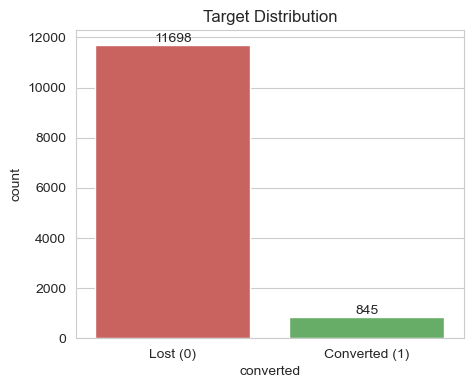

In [8]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(x='converted', data=df_model, palette=['#d9534f', '#5cb85c'])
ax.set_xticklabels(['Lost (0)', 'Converted (1)'])
ax.set_title('Target Distribution')
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
plt.show()

#Handle Missing Values

In [9]:
df_model.isnull().sum()

creation_date            0
first_call_attempt     769
lead_status              0
lead_stage               0
lead_tag              1290
assigned_to              0
last_call_date         769
campaign_name            0
source_type              0
converted                0
dtype: int64

#Feature Engineering

In [10]:
def create_features(data):
    data = data.copy()

    # Convert text dates (day-month-year) to real datetime values
    date_format = '%d-%m-%Y %H:%M'
    data['creation_date']      = pd.to_datetime(data['creation_date'],      format=date_format)
    data['first_call_attempt'] = pd.to_datetime(data['first_call_attempt'], format=date_format)
    data['last_call_date']     = pd.to_datetime(data['last_call_date'],     format=date_format)

    # New features
    data['called'] = data['first_call_attempt'].notna().astype(int)
    data['creation_hour'] = data['creation_date'].dt.hour
    data['creation_dayofweek'] = data['creation_date'].dt.dayofweek
    data['hours_to_first_call'] = (data['first_call_attempt'] - data['creation_date']).dt.total_seconds() / 3600
    data['call_span_hours'] = (data['last_call_date'] - data['first_call_attempt']).dt.total_seconds() / 3600

    # Never-called leads have no gap, so fill with 0 (the 'called' column already tells us they were not called)
    data['hours_to_first_call'] = data['hours_to_first_call'].fillna(0)
    data['call_span_hours'] = data['call_span_hours'].fillna(0)
    return data

df_model = create_features(df_model)
df_open  = create_features(df_open)

df_model[['creation_date', 'called', 'creation_hour', 'creation_dayofweek',
          'hours_to_first_call', 'call_span_hours', 'converted']].head()

,creation_date,called,creation_hour,creation_dayofweek,hours_to_first_call,call_span_hours,converted
594,2025-12-25 10:06:00,1,10,3,26.416667,0.000000,0
607,2025-12-25 08:05:00,1,8,3,5.100000,0.000000,0
614,2025-12-25 06:59:00,1,6,3,5.066667,0.916667,0
616,2025-12-25 04:34:00,1,4,3,8.616667,0.000000,0
637,2025-12-24 20:51:00,1,20,2,18.633333,0.000000,0


#Remove Data Leakage

In [11]:
print(pd.crosstab(df_model['lead_tag'].fillna('NO TAG'), df_model['converted']))
print()
print(pd.crosstab(df_model['lead_status'], df_model['converted']))

converted                0    1
lead_tag                       
NO TAG                 445  845
already-purchased       29    0
call-not-connected      52    0
lost-to-competition    303    0
not-interested       10869    0

converted                                  0    1
lead_status                                      
CLOSED                                 11362  845
NOT CONNECTED - CLOSED BY SYSTEM         328    0
NOT CONNECTED - RESCHEDULED BY SYSTEM      8    0


In [12]:
FEATURES = ['assigned_to', 'campaign_name', 'source_type',
            'called', 'creation_hour', 'creation_dayofweek',
            'hours_to_first_call', 'call_span_hours']

CAT_COLS = ['assigned_to', 'campaign_name', 'source_type']            # text columns
NUM_COLS = ['creation_hour', 'creation_dayofweek', 'hours_to_first_call', 'call_span_hours']

print('Final input features:', FEATURES)
print('Missing values in features:', df_model[FEATURES].isnull().sum().sum())

Final input features: ['assigned_to', 'campaign_name', 'source_type', 'called', 'creation_hour', 'creation_dayofweek', 'hours_to_first_call', 'call_span_hours']
Missing values in features: 0


#EDA

In [13]:
def plot_conversion_rate(col, min_count=50, top_n=15, figsize=(8, 5)):
    summary = df_model.groupby(col)['converted'].agg(['count', 'mean'])
    summary.columns = ['total_leads', 'conversion_rate_%']
    summary['conversion_rate_%'] = (summary['conversion_rate_%'] * 100).round(2)
    summary = summary[summary['total_leads'] >= min_count]
    summary = summary.sort_values('conversion_rate_%', ascending=False).head(top_n)

    plt.figure(figsize=figsize)
    sns.barplot(x=summary['conversion_rate_%'], y=summary.index.astype(str), palette='viridis')
    plt.axvline(df_model['converted'].mean() * 100, color='red', linestyle='--', label='Overall average')
    plt.title('Conversion Rate by ' + col)
    plt.xlabel('Conversion rate (%)')
    plt.legend()
    plt.show()
    return summary

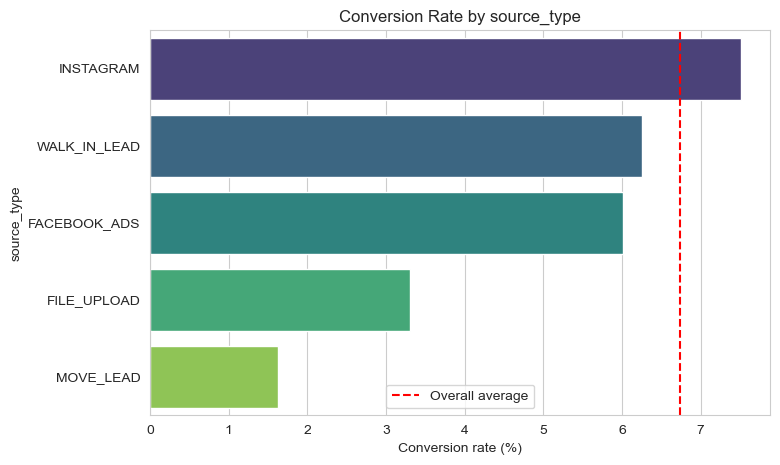

,total_leads,conversion_rate_%
source_type,,
INSTAGRAM,10214,7.51
WALK_IN_LEAD,16,6.25
FACEBOOK_ADS,716,6.01
FILE_UPLOAD,484,3.31
MOVE_LEAD,1112,1.62


In [14]:
plot_conversion_rate('source_type', min_count=10)

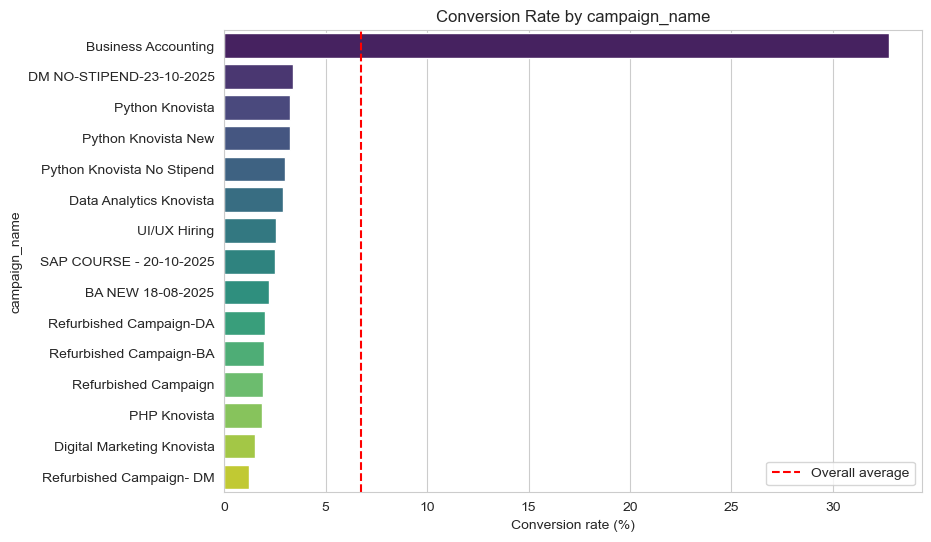

,total_leads,conversion_rate_%
campaign_name,,
Business Accounting,1725,32.75
DM NO-STIPEND-23-10-2025,118,3.39
Python Knovista,2109,3.22
Python Knovista New,1489,3.22
Python Knovista No Stipend,168,2.98
Data Analytics Knovista,2001,2.90
UI/UX Hiring,277,2.53
SAP COURSE - 20-10-2025,121,2.48
BA NEW 18-08-2025,1489,2.22


In [15]:
plot_conversion_rate('campaign_name', min_count=100, figsize=(9, 6))

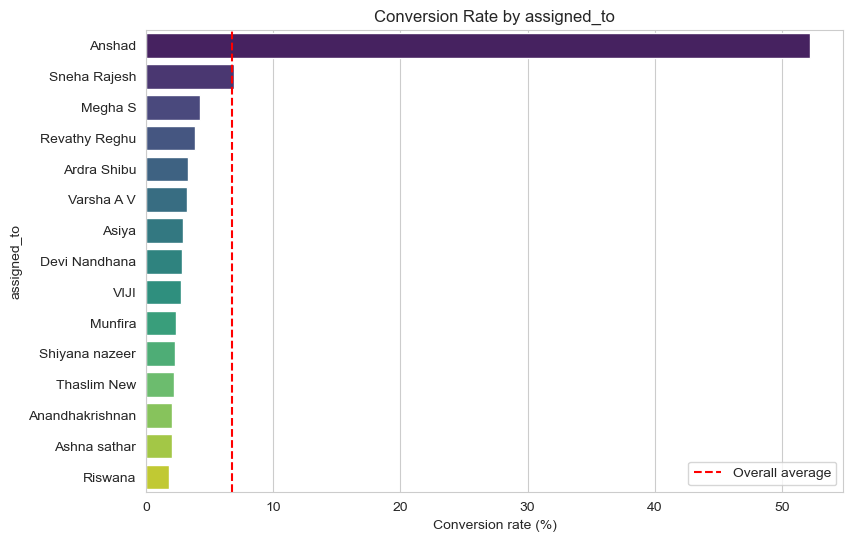

,total_leads,conversion_rate_%
assigned_to,,
Anshad,1065,52.21
Sneha Rajesh,158,6.96
Megha S,1443,4.23
Revathy Reghu,1253,3.83
Ardra Shibu,419,3.34
Varsha A V,125,3.20
Asiya,207,2.90
Devi Nandhana,175,2.86
VIJI,544,2.76


In [16]:
plot_conversion_rate('assigned_to', min_count=100, figsize=(9, 6))

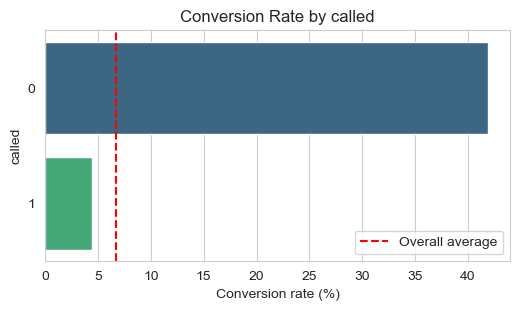

,total_leads,conversion_rate_%
called,,
0,769,41.87
1,11774,4.44


In [17]:
plot_conversion_rate('called', min_count=1, figsize=(6, 3))

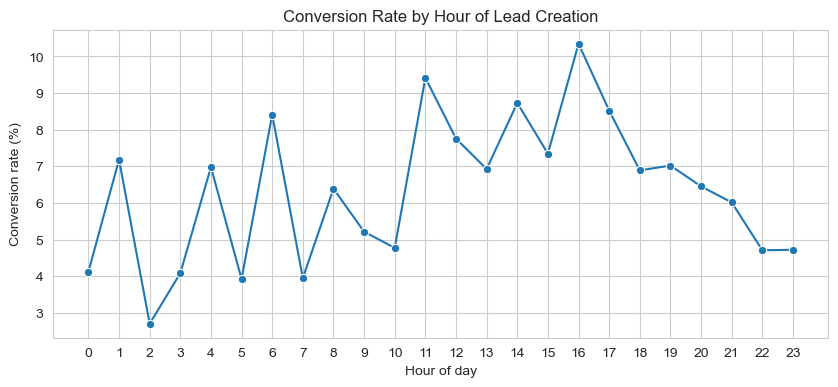

In [18]:
hourly = df_model.groupby('creation_hour')['converted'].mean() * 100
plt.figure(figsize=(10, 4))
sns.lineplot(x=hourly.index, y=hourly.values, marker='o')
plt.title('Conversion Rate by Hour of Lead Creation')
plt.xlabel('Hour of day')
plt.ylabel('Conversion rate (%)')
plt.xticks(range(0, 24))
plt.show()

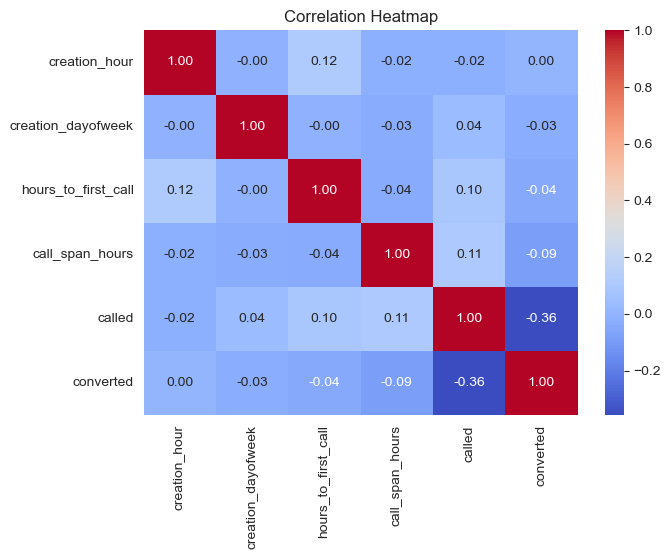

In [19]:
plt.figure(figsize=(7, 5))
sns.heatmap(df_model[NUM_COLS + ['called', 'converted']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

#Encode Categorical Variables

In [20]:
X = pd.get_dummies(df_model[FEATURES], columns=CAT_COLS, dtype=int)
y = df_model['converted']

print('Shape of X (rows, columns):', X.shape)
X.head()

Shape of X (rows, columns): (12543, 60)


,called,creation_hour,creation_dayofweek,hours_to_first_call,call_span_hours,assigned_to_Akhil M A,assigned_to_Amghitha,assigned_to_Anandhakrishnan,assigned_to_Anshad,assigned_to_Ardra,assigned_to_Ardra Shibu,assigned_to_Arunkumar,assigned_to_Ashna sathar,assigned_to_Asiya,assigned_to_Devi Nandhana,assigned_to_Dharshana,assigned_to_Hamza Anzar,assigned_to_Megha S,assigned_to_Munfira,assigned_to_Revathy Reghu,assigned_to_Riswana,assigned_to_Sherin Shaji,assigned_to_Shilpa Sudhakaran,assigned_to_Shiyana nazeer,assigned_to_Sneha Rajesh,assigned_to_Thaslim New,assigned_to_VIJI,assigned_to_Varsha A V,campaign_name_BA NEW 18-08-2025,campaign_name_BA NO STIPEND 28-10-2025,campaign_name_Business Accounting,campaign_name_Common Ads 21-08-2025,campaign_name_DM NO-STIPEND-23-10-2025,campaign_name_Data Analytics Knovista,campaign_name_Digital Marketing Knovista,campaign_name_Digital Marketing Learning Knovista,campaign_name_IT DUMB,campaign_name_PHP Knovista,campaign_name_PHP Knovista New,campaign_name_Performance Marketing Knovista,campaign_name_Python Knovista,campaign_name_Python Knovista New,campaign_name_Python Knovista No Stipend,campaign_name_Refurbished Campaign,campaign_name_Refurbished Campaign- DM,campaign_name_Refurbished Campaign- UI/UX,campaign_name_Refurbished Campaign-BA,campaign_name_Refurbished Campaign-DA,campaign_name_Refurbished Campaign-PHP,campaign_name_Refurbished Campaign-PYTHON,campaign_name_SAP COURSE - 20-10-2025,campaign_name_SAP Knovista,campaign_name_UI/UX Hiring,campaign_name_UI/UX no Stipend,source_type_FACEBOOK_ADS,source_type_FILE_UPLOAD,source_type_INSTAGRAM,source_type_MOVE_LEAD,source_type_NEODOVE_DIAL_PAD,source_type_WALK_IN_LEAD
594,1,10,3,26.416667,0.000000,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
607,1,8,3,5.100000,0.000000,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
614,1,6,3,5.066667,0.916667,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
616,1,4,3,8.616667,0.000000,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
637,1,20,2,18.633333,0.000000,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


#Train / Test Split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Training set:', X_train.shape)
print('Test set    :', X_test.shape)
print('Conversion rate in train: {:.2f}%'.format(y_train.mean() * 100))
print('Conversion rate in test : {:.2f}%'.format(y_test.mean() * 100))

Training set: (10034, 60)
Test set    : (2509, 60)
Conversion rate in train: 6.74%
Conversion rate in test : 6.74%


In [22]:
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[NUM_COLS] = scaler.fit_transform(X_train[NUM_COLS])
X_test_scaled[NUM_COLS] = scaler.transform(X_test[NUM_COLS])

#Train the Models

In [23]:
imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced_subsample',
                                            random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                             scale_pos_weight=imbalance_ratio, eval_metric='logloss', random_state=42)
}

trained_models = {}
for name, model in models.items():
    if name == 'Logistic Regression':
        model.fit(X_train_scaled, y_train)      # uses scaled data
    else:
        model.fit(X_train, y_train)
    trained_models[name] = model
    print(name, 'trained')

Logistic Regression trained
Decision Tree trained
Random Forest trained
XGBoost trained


#Model Evaluation

In [24]:
def get_test_data(name):
    return X_test_scaled if name == 'Logistic Regression' else X_test

results = []
for name, model in trained_models.items():
    Xt = get_test_data(name)
    y_pred = model.predict(Xt)
    y_prob = model.predict_proba(Xt)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index('Model').round(3)
results_df.sort_values('ROC-AUC', ascending=False)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Random Forest,0.955,0.692,0.598,0.641,0.873
XGBoost,0.929,0.483,0.675,0.563,0.871
Decision Tree,0.870,0.299,0.698,0.419,0.856
Logistic Regression,0.918,0.427,0.645,0.514,0.847


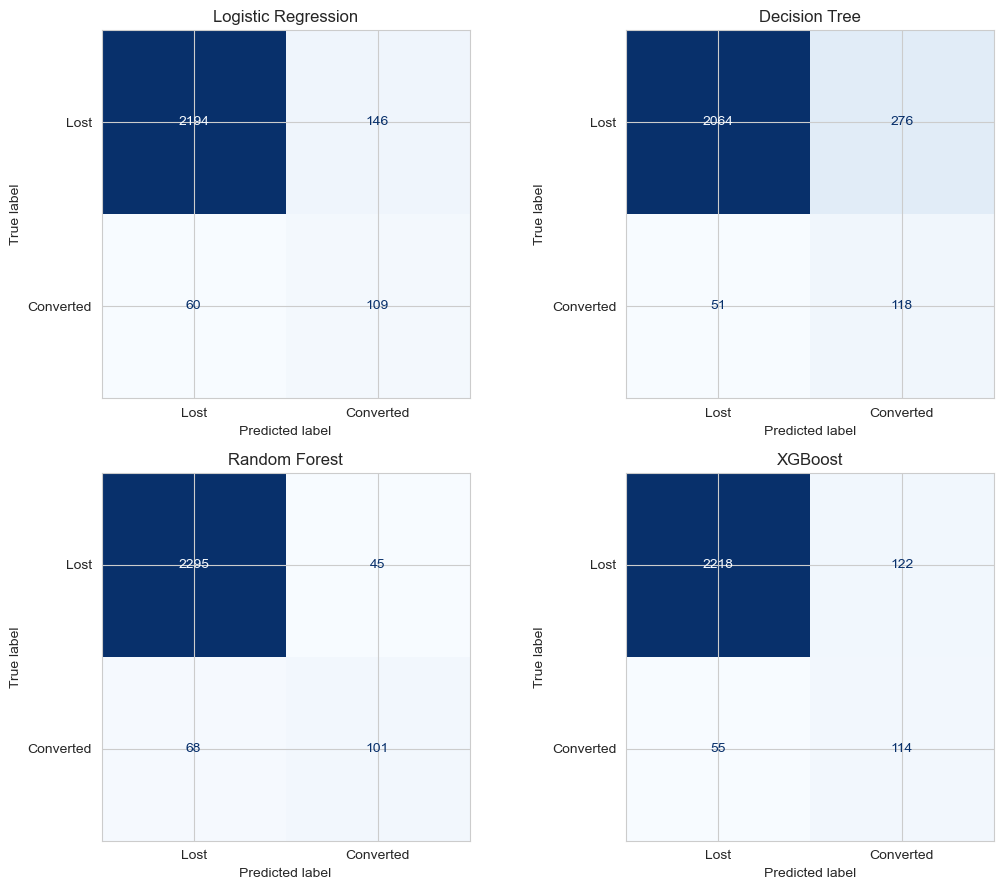

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, model) in zip(axes.ravel(), trained_models.items()):
    y_pred = model.predict(get_test_data(name))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=['Lost', 'Converted']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

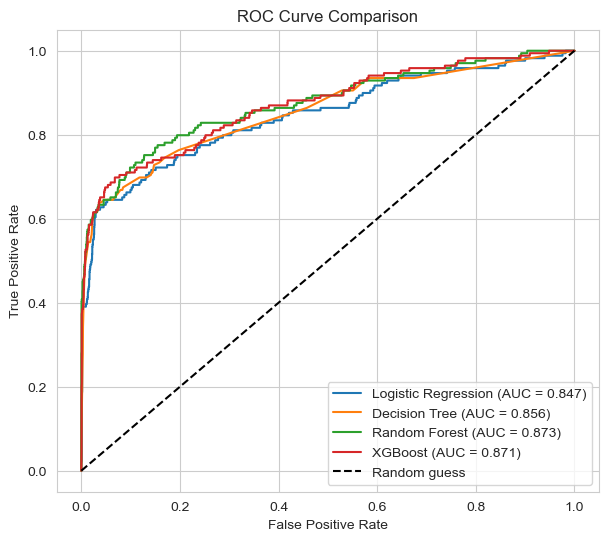

In [26]:
plt.figure(figsize=(7, 6))
for name, model in trained_models.items():
    y_prob = model.predict_proba(get_test_data(name))[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label='{} (AUC = {:.3f})'.format(name, roc_auc_score(y_test, y_prob)))
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

In [27]:
final_model = trained_models['Random Forest']
y_pred_final = final_model.predict(X_test)
print(classification_report(y_test, y_pred_final, target_names=['Lost', 'Converted']))

              precision    recall  f1-score   support

        Lost       0.97      0.98      0.98      2340
   Converted       0.69      0.60      0.64       169

    accuracy                           0.95      2509
   macro avg       0.83      0.79      0.81      2509
weighted avg       0.95      0.95      0.95      2509



#Feature Importance

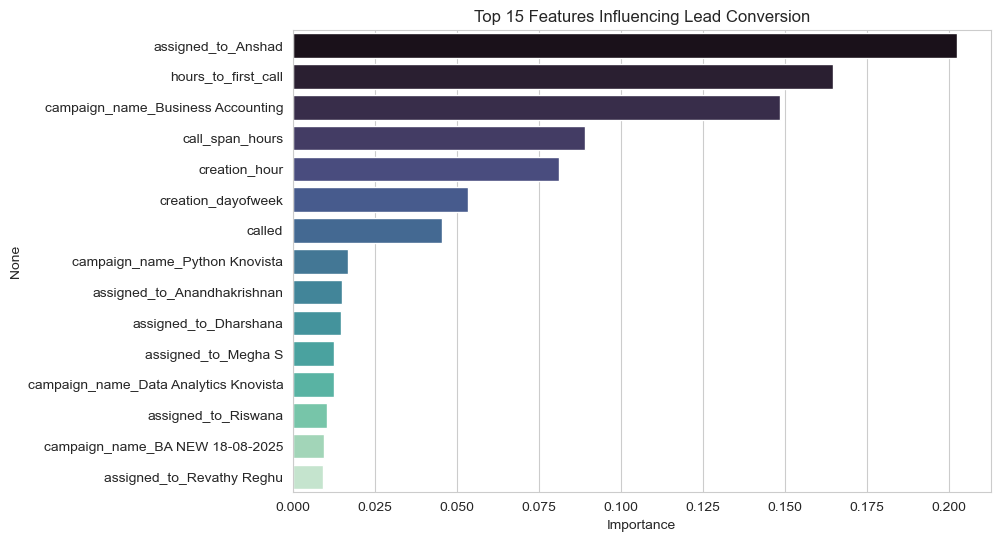

assigned_to_Anshad                       0.2025
hours_to_first_call                      0.1646
campaign_name_Business Accounting        0.1483
call_span_hours                          0.0891
creation_hour                            0.0810
creation_dayofweek                       0.0534
called                                   0.0455
campaign_name_Python Knovista            0.0167
assigned_to_Anandhakrishnan              0.0148
assigned_to_Dharshana                    0.0145
assigned_to_Megha S                      0.0124
campaign_name_Data Analytics Knovista    0.0124
assigned_to_Riswana                      0.0103
campaign_name_BA NEW 18-08-2025          0.0094
assigned_to_Revathy Reghu                0.0091
dtype: float64

In [28]:
importance = pd.Series(final_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(x=importance.head(15).values, y=importance.head(15).index, palette='mako')
plt.title('Top 15 Features Influencing Lead Conversion')
plt.xlabel('Importance')
plt.show()

importance.head(15).round(4)

#Prediction System

In [29]:
def predict_new_lead(lead, model=final_model):
    row = pd.DataFrame([lead])

    # Same cleaning as training
    for col in CAT_COLS:
        row[col] = row[col].str.strip()

    # Same feature engineering as training
    row = create_features(row)

    # Same encoding as training. reindex() makes the columns exactly match the training columns.
    row_encoded = pd.get_dummies(row[FEATURES], columns=CAT_COLS, dtype=int)
    row_encoded = row_encoded.reindex(columns=X.columns, fill_value=0)

    prob = float(model.predict_proba(row_encoded)[0, 1])
    label = 'Will Convert' if prob >= 0.5 else 'Will Not Convert'
    priority = 'High' if prob >= 0.5 else ('Medium' if prob >= 0.3 else 'Low')

    return {'prediction': label, 'conversion_probability_%': round(prob * 100, 2), 'priority': priority}

In [30]:
new_lead_1 = {
    'assigned_to': 'Anshad',
    'campaign_name': 'Business Accounting',
    'source_type': 'INSTAGRAM',
    'creation_date': '10-01-2026 15:30',
    'first_call_attempt': '10-01-2026 16:30',
    'last_call_date': '11-01-2026 11:00'
}

new_lead_2 = {
    'assigned_to': 'Megha S',
    'campaign_name': 'Business Accounting',
    'source_type': 'INSTAGRAM',
    'creation_date': '10-01-2026 15:30',
    'first_call_attempt': '10-01-2026 16:30',
    'last_call_date': '11-01-2026 11:00'
}

new_lead_3 = {
    'assigned_to': 'Dharshana',
    'campaign_name': 'Digital Marketing Knovista',
    'source_type': 'MOVE_LEAD',
    'creation_date': '10-01-2026 23:10',
    'first_call_attempt': None,
    'last_call_date': None
}

print('Lead 1:', predict_new_lead(new_lead_1))
print('Lead 2:', predict_new_lead(new_lead_2))
print('Lead 3:', predict_new_lead(new_lead_3))

Lead 1: {'prediction': 'Will Convert', 'conversion_probability_%': 57.6, 'priority': 'High'}
Lead 2: {'prediction': 'Will Not Convert', 'conversion_probability_%': 11.88, 'priority': 'Low'}
Lead 3: {'prediction': 'Will Not Convert', 'conversion_probability_%': 6.91, 'priority': 'Low'}


In [31]:
X_open = pd.get_dummies(df_open[FEATURES], columns=CAT_COLS, dtype=int)
X_open = X_open.reindex(columns=X.columns, fill_value=0)

df_open['conversion_probability_%'] = (final_model.predict_proba(X_open)[:, 1] * 100).round(2)
df_open['priority'] = pd.cut(df_open['conversion_probability_%'],
                             bins=[-0.01, 30, 50, 100], labels=['Low', 'Medium', 'High'])

print(df_open['priority'].value_counts())

top_leads = df_open.sort_values('conversion_probability_%', ascending=False)
top_leads[['lead_stage', 'assigned_to', 'campaign_name', 'source_type',
           'conversion_probability_%', 'priority']].head(10)

priority
Low       13571
Medium      807
High        454
Name: count, dtype: int64


,lead_stage,assigned_to,campaign_name,source_type,conversion_probability_%,priority
14426,Prospect,Anshad,Business Accounting,INSTAGRAM,98.88,High
12498,Prospect,Anshad,Business Accounting,INSTAGRAM,98.88,High
12612,Prospect,Anshad,Business Accounting,INSTAGRAM,98.88,High
13529,Prospect,Anshad,Business Accounting,INSTAGRAM,98.87,High
13197,Prospect,Anshad,Business Accounting,INSTAGRAM,98.87,High
16095,Prospect,Anshad,Business Accounting,INSTAGRAM,98.83,High
15149,Prospect,Anshad,Business Accounting,INSTAGRAM,98.80,High
13287,Prospect,Anshad,Business Accounting,INSTAGRAM,98.76,High
12485,Prospect,Anshad,Business Accounting,INSTAGRAM,98.74,High
12490,Prospect,Anshad,Business Accounting,INSTAGRAM,98.74,High


In [32]:
joblib.dump(final_model, 'lead_conversion_model.pkl')
joblib.dump(list(X.columns), 'model_columns.pkl')
top_leads.to_csv('scored_open_leads.csv', index=False)
print('Saved: lead_conversion_model.pkl, model_columns.pkl, scored_open_leads.csv (in your notebook folder)')

Saved: lead_conversion_model.pkl, model_columns.pkl, scored_open_leads.csv (in your notebook folder)


Project Summary — Lead Conversion Prediction using Machine Learning

Problem: Predict whether a lead will convert into a customer, so the sales team can prioritize follow-ups.

Data: 27,375 leads from Knovista's CRM (Instagram, Facebook Ads, file uploads, etc.). Of these, 12,543 have a known outcome (845 Converted, 11,698 Lost) — a 6.7% conversion rate — and 14,832 are still open

Approach:

-> Cleaned the data (removed duplicates, fixed inconsistent salesperson names, dropped identifier columns like name/phone/email and the empty references column).

-> Defined the target as Converted (1) vs Lost (0), using only the closed leads for training.

-> Engineered features from dates and call history: called, hours_to_first_call, call_span_hours, creation_hour, creation_dayofweek.

-> Removed lead_status and lead_tag as data leakage — both are set after the outcome is already known.

-> One-hot encoded categorical columns, split 80/20 (stratified), and trained 4 models: Logistic Regression, Decision Tree, Random Forest, XGBoost — all with class-balancing since the data is imbalanced.

Results:

Model	                Recall	      F1	   ROC-AUC
Random Forest (final)	0.60         0.64	   0.873
XGBoost	                0.68	     0.56	   0.871
Decision Tree	        0.70	     0.42	   0.856
Logistic Regression	    0.65	     0.51	   0.847


Key insights:
             Conversion is driven mainly by the assigned salesperson, the campaign (Business Accounting converts ~33% vs 1–3% for most others), and how quickly a lead is called. Instagram and Facebook Ads outperform MOVE_LEAD and FILE_UPLOAD as sources.


Outcome delivered:
                  A trained model, a predict_new_lead() function for scoring one lead at a time, and a full ranked list of the 14,832 open leads by conversion probability (454 High, 807 Medium, 13,571 Low priority) — giving the sales team a ready priority list.

Limitation: 
            Never-called leads show an unusually high conversion rate, largely reflecting one salesperson's workflow rather than a general pattern — worth noting if asked in review.

